## <font color = #0288d1>多层模型和激活函数</font>

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.transforms import Compose, ToTensor, Normalize
from torchvision import datasets

In [ ]:
mean = torch.tensor(0.1307)
std = torch.tensor(0.3081)
compose = Compose([ToTensor(), Normalize(mean,std)])
train_dataset = datasets.MNIST('./data', train=True, transform=compose, download=False)
test_dataset =  datasets.MNIST('./data', train=False, transform=compose, download=False)
train_loader = DataLoader(train_dataset, batch_size=10000, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2000)

In [ ]:
def mini_batch_train(data_loader,model,optimizer,loss_fn):
    mini_batch_losses = []
    for x_batch, y_batch in data_loader:
        # 置为训练状态
        model.train()
        # Step 1 - 前向计算预测值
        yhat = model(x_batch)
        # Step 2 - 计算损失
        mini_batch_loss = loss_fn(yhat, y_batch)
        # Step 3 - 计算梯度
        mini_batch_loss.backward()
        # Step 4 - 参数更新
        optimizer.step()
        optimizer.zero_grad()

        mini_batch_losses.append(mini_batch_loss.item())
                  
    loss = np.mean(mini_batch_losses)
    return loss

In [ ]:
def mini_batch_val(data_loader,model,loss_fn):
    mini_batch_losses = []
    for x_batch, y_batch in data_loader:
        # 置为验证状态
        model.eval()
        # Step 1 - 前向计算预测值
        yhat = model(x_batch)
        # Step 2 - 计算损失
        mini_batch_loss = loss_fn(yhat, y_batch)
        mini_batch_losses.append(mini_batch_loss.item())
                  
    loss = np.mean(mini_batch_losses)
    return loss

In [ ]:
def train(model, train_loader, test_loader, loss_fn, optimizer, epochs):
    # 指定随机数种子，可以再现数据
    np.random.seed(23)
    torch.manual_seed(23)

    losses = []  # 每轮训练的损失
    val_losses = [] #  每轮验证数据的损失

    for epoch in range(epochs):
        model.train()
         # 进入mini-batch的内循环
        loss = mini_batch_train(train_loader,model,optimizer,loss_fn)
        losses.append(loss)

        # 验证数据集（验证不需要计算梯度）
        with torch.inference_mode():
            # 验证集的 mini_batch
            val_loss = mini_batch_val(test_loader,model,loss_fn)
            val_losses.append(val_loss)
        print(f'epoch:{epoch},loss:{loss},val_loss:{val_loss}')
    return losses, val_losses

In [2]:
class ImageDeepModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784,392)
        self.fc2 = nn.Linear(392,196)
        self.fc3 = nn.Linear(196,98)
        self.fc4 = nn.Linear(98,10)
        
    def forward(self, x):
        x=self.flatten(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        return self.fc4(x)
       

In [3]:
model = ImageDeepModel()

In [ ]:
model = ImageDeepModel()
lr = 3e-3
epochs = 50
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

In [ ]:
train_loss, val_loss = train(model, train_loader, test_loader, loss_fn, optimizer, epochs)

In [4]:
# torch.save(model.state_dict(), "./data/MNIST_deep.pth")
model.load_state_dict(torch.load("./data/MNIST_deep.pth"))

<All keys matched successfully>

In [ ]:
# losses = {'train_loss':train_loss, 'val_loss':val_loss}
# torch.save(losses,'./data/losses_deep.pth')
losses = torch.load('./data/losses.pth',weights_only=False)
train_loss = losses['train_loss']
val_loss = losses['val_loss']

In [ ]:
plt.style.use('fivethirtyeight')
def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_loss, label='Training Loss', c='b')
    plt.plot(val_loss, label='Validation Loss', c='r')
    plt.yscale('log')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.tight_layout()
    return fig

fig=plot_losses()

In [ ]:
import torchmetrics
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=10)
with torch.inference_mode():
    for x,y in test_loader:
        yhat = model(x)
        accuracy(yhat, y)
acc = accuracy.compute()
print(f"Test Accuracy: {acc.item() * 100:.2f}%")

In [ ]:
# 1. 先遍历测试集，拿到所有错误样本全局下标、图像、预测/真实标签
all_wrong_indices = []
all_wrong_imgs = []
all_wrong_preds = []
all_wrong_labels = []
batch_offset = 0

with torch.inference_mode():
    for x, y in test_loader:
        bs = x.size(0)
        logits = model(x)
        pred = torch.argmax(logits, dim=1)
        mask = pred != y

        if mask.any():
            local_idx = torch.nonzero(mask, as_tuple=True)[0]
            global_idx = local_idx + batch_offset
            
            all_wrong_indices.extend(global_idx.tolist())
            all_wrong_imgs.append(x[mask])
            all_wrong_preds.append(pred[mask])
            all_wrong_labels.append(y[mask])
        
        batch_offset += bs

# 拼接所有错误数据
wrong_imgs = torch.cat(all_wrong_imgs)
wrong_preds = torch.cat(all_wrong_preds)
wrong_labels = torch.cat(all_wrong_labels)

# 2. 展示前10个错误样本
# 最多取10个，不足10个则显示全部
show_num = min(10, len(wrong_imgs))
fig, ax = plt.subplots(1, show_num)

for i in range(show_num):
    # 转为numpy绘图 (适配手写数字单通道图)
    img = wrong_imgs[i][0].numpy()
    ax[i].imshow(img, cmap='gray')
    # 标题标注 真实值/预测值
    ax[i].set_title(f"T:{wrong_labels[i].item()}\nP:{wrong_preds[i].item()}")
    ax[i].axis('off')

plt.tight_layout()
plt.show()

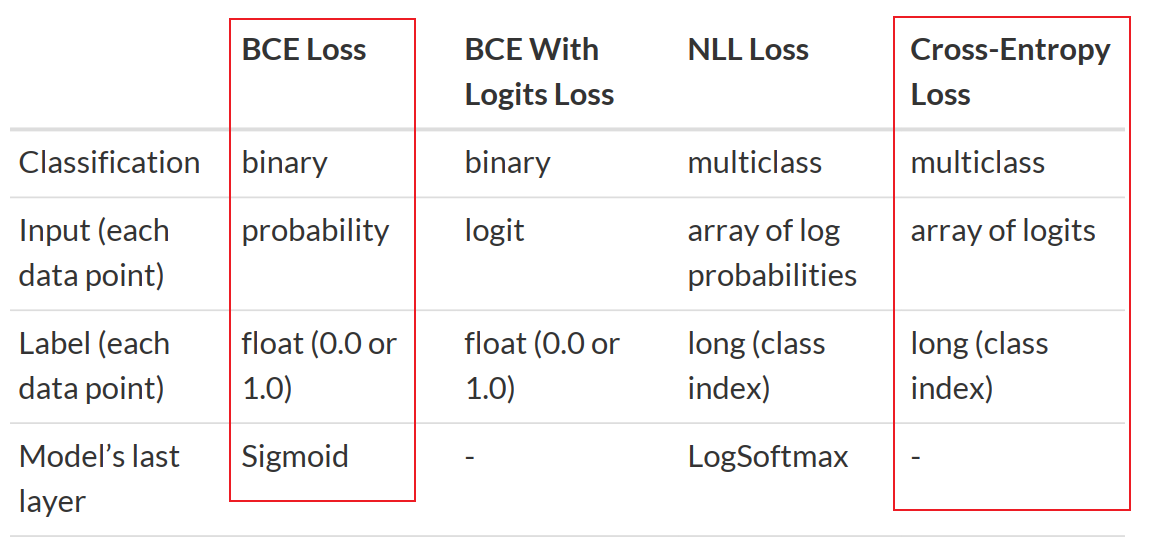